In [87]:
!pip install tiktoken -q

In [88]:
import torch
import torch.nn as nn

import pandas as pd
import numpy as np

import tiktoken

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt

torch.manual_seed(1)
np.random.seed(1)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using:", device)

Using: cpu


In [89]:
df = pd.read_csv(
    "IMDB Dataset.csv",
    nrows=3000
)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (3000, 2)

Columns:
Index(['review', 'sentiment'], dtype='object')

First 5 rows:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [90]:
print("Dataset shape:", df.shape)

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (3000, 2)

Sentiment distribution:
sentiment
positive    1508
negative    1492
Name: count, dtype: int64

Missing values:
review       0
sentiment    0
dtype: int64


In [91]:
df["label"] = df["sentiment"].map({
    "positive": 1,
    "negative": 0
})

print(df[["sentiment", "label"]].head(10))

  sentiment  label
0  positive      1
1  positive      1
2  positive      1
3  negative      0
4  positive      1
5  positive      1
6  positive      1
7  negative      0
8  negative      0
9  positive      1


In [92]:
texts = df["review"].astype(str).values
labels = df["label"].values

print("Number of reviews:", len(texts))
print("Number of labels :", len(labels))

Number of reviews: 3000
Number of labels : 3000


In [93]:
X_train, X_test, y_train, y_test = train_test_split(
    texts,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

Training samples: 2400
Testing samples : 600


In [94]:
tokenizer = tiktoken.get_encoding("cl100k_base")

print("Tokenizer:", tokenizer.name)
print("Vocabulary size:", tokenizer.n_vocab)

Tokenizer: cl100k_base
Vocabulary size: 100277


In [95]:
sample_text = X_train[0]

tokens = tokenizer.encode(sample_text)

print("Original text:")
print(sample_text[:500])

print("\nToken IDs:")
print(tokens[:30])

print("\nNumber of tokens:", len(tokens))

Original text:
I have always loved the ironic symbolism and brilliant cinematography of Coppola's masterpiece. I was lucky enough to meet Martin Sheen outside the Santa Monica Civic Auditorium one night in 1981, as he waited for Charlie and Emilio to leave a concert. He was very humble about the praise I shared with him for this work of art, especially his portrayal of the young Captain. This is, without a doubt, a must see, a complete 10 and an important part of American Film History. "Charlie Don't Surf". Ro

Token IDs:
[40, 617, 2744, 10456, 279, 59560, 83476, 323, 20333, 88122, 5814, 315, 82099, 8083, 596, 59831, 13, 358, 574, 18069, 3403, 311, 3449, 11826, 3005, 268, 4994, 279, 16376, 46844]

Number of tokens: 169


In [96]:
def encode_text(text):
    tokens = tokenizer.encode(text)

    # +1 because 0 will be reserved for padding
    tokens = [token + 1 for token in tokens]

    return tokens

In [97]:
encoded_sample = encode_text(sample_text)

print("Encoded tokens:")
print(encoded_sample[:30])

print("\nNumber of tokens:", len(encoded_sample))

Encoded tokens:
[41, 618, 2745, 10457, 280, 59561, 83477, 324, 20334, 88123, 5815, 316, 82100, 8084, 597, 59832, 14, 359, 575, 18070, 3404, 312, 3450, 11827, 3006, 269, 4995, 280, 16377, 46845]

Number of tokens: 169


In [98]:
MAX_LENGTH = 200

print("Maximum sequence length:", MAX_LENGTH)

Maximum sequence length: 200


In [99]:
def pad_or_truncate(sequence, max_length=MAX_LENGTH):

    # Truncate long sequences
    if len(sequence) > max_length:
        return sequence[:max_length]

    # Pad short sequences with 0
    return sequence + [0] * (max_length - len(sequence))

In [100]:
test_sequence = encode_text(sample_text)

processed_sequence = pad_or_truncate(test_sequence)

print("Original token count:", len(test_sequence))
print("Processed token count:", len(processed_sequence))

print("\nFirst 20 tokens:")
print(processed_sequence[:20])

print("\nLast 20 tokens:")
print(processed_sequence[-20:])

Original token count: 169
Processed token count: 200

First 20 tokens:
[41, 618, 2745, 10457, 280, 59561, 83477, 324, 20334, 88123, 5815, 316, 82100, 8084, 597, 59832, 14, 359, 575, 18070]

Last 20 tokens:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [101]:
X_train_encoded = [
    pad_or_truncate(
        encode_text(text)
    )
    for text in X_train
]

print("Number of training sequences:", len(X_train_encoded))
print("Length of first sequence:", len(X_train_encoded[0]))

Number of training sequences: 2400
Length of first sequence: 200


In [102]:
X_test_encoded = [
    pad_or_truncate(
        encode_text(text)
    )
    for text in X_test
]

print("Number of testing sequences:", len(X_test_encoded))
print("Length of first sequence:", len(X_test_encoded[0]))

Number of testing sequences: 600
Length of first sequence: 200


In [103]:
X_train_tensor = torch.tensor(
    X_train_encoded,
    dtype=torch.long
)

X_test_tensor = torch.tensor(
    X_test_encoded,
    dtype=torch.long
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.float32
)

print("X_train:", X_train_tensor.shape)
print("X_test :", X_test_tensor.shape)
print("y_train:", y_train_tensor.shape)
print("y_test :", y_test_tensor.shape)

X_train: torch.Size([2400, 200])
X_test : torch.Size([600, 200])
y_train: torch.Size([2400])
y_test : torch.Size([600])


In [104]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches :", len(test_loader))

Training batches: 75
Testing batches : 19


In [105]:
print("First review tensor:")
print(X_train_tensor[0])

print("\nFirst review label:")
print(y_train_tensor[0])

First review tensor:
tensor([   41,   618,  2745, 10457,   280, 59561, 83477,   324, 20334, 88123,
         5815,   316, 82100,  8084,   597, 59832,    14,   359,   575, 18070,
         3404,   312,  3450, 11827,  3006,   269,  4995,   280, 16377, 46845,
        55930, 62493,  2412,   833,  3815,   305,   221,  3754,    17,    12,
          440,   569, 30316,   370, 25973,   324,  5868, 34430,   312,  5388,
          265, 21498,    14,  1284,   575,  1634, 39613,   923,   280, 29489,
          359,  6223,   450,  1462,   370,   421,   991,   316,  1990,    12,
         5424,   814, 75034,   316,   280,  3996, 22023,    14,  1116,   375,
           12,  2086,   265, 10713,    12,   265,  2012,  1519,    12,   265,
         4687,   221,   606,   324,   460,  3063,   962,   316,  3779, 17043,
        11347,    14,   331, 73729,  4419,   957, 65198,  3344,  8564,   424,
        12329,   544,   597, 11496,  1585,   321,  1821,  1024,   833,     9,
         1588,   540,  1206, 40917,   440, 

In [106]:
class MovieRNN(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.output = nn.Linear(
            hidden_dim,
            1
        )

    def forward(self, x):

        x = self.embedding(x)

        _, hidden = self.rnn(x)

        output = self.output(hidden[-1])

        return output.squeeze(1)

In [107]:
VOCAB_SIZE = tokenizer.n_vocab + 1

movie = MovieRNN(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=128
).to(device)

print(movie)

MovieRNN(
  (embedding): Embedding(100278, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (output): Linear(in_features=128, out_features=1, bias=True)
)


In [108]:
loss_fn = nn.BCEWithLogitsLoss()

In [109]:
optimizer = torch.optim.Adam(
    movie.parameters(),
    lr=0.0005
)

In [110]:
print("Training tensor:", X_train_tensor.shape)
print("Testing tensor :", X_test_tensor.shape)

Training tensor: torch.Size([2400, 200])
Testing tensor : torch.Size([600, 200])


In [111]:
EPOCHS = 15

train_losses = []

for epoch in range(EPOCHS):

    movie.train()

    total_loss = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = movie(inputs)

        loss = loss_fn(
            logits,
            labels
        )

        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            movie.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    train_losses.append(avg_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"- Loss: {avg_loss:.4f}"
    )

Epoch 1/15 - Loss: 0.7000
Epoch 2/15 - Loss: 0.6733
Epoch 3/15 - Loss: 0.6462
Epoch 4/15 - Loss: 0.6119
Epoch 5/15 - Loss: 0.5711
Epoch 6/15 - Loss: 0.5416
Epoch 7/15 - Loss: 0.4887
Epoch 8/15 - Loss: 0.4461
Epoch 9/15 - Loss: 0.4088
Epoch 10/15 - Loss: 0.3771
Epoch 11/15 - Loss: 0.3717
Epoch 12/15 - Loss: 0.3595
Epoch 13/15 - Loss: 0.3818
Epoch 14/15 - Loss: 0.3240
Epoch 15/15 - Loss: 0.3216


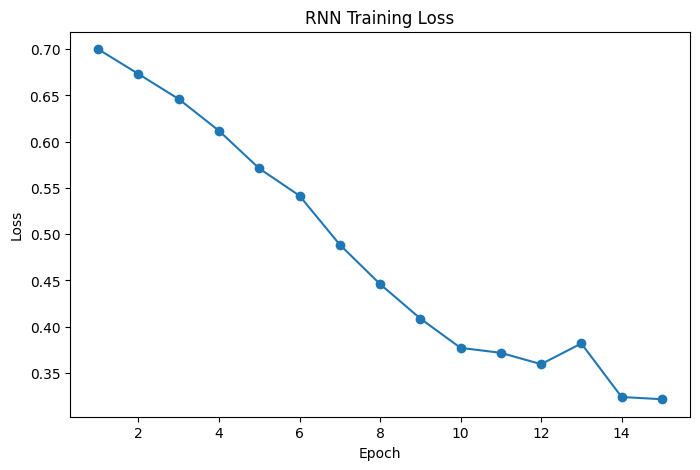

In [112]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN Training Loss")

plt.show()

In [113]:
movie.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        logits = movie(inputs)

        probabilities = torch.sigmoid(logits)

        predictions = (
            probabilities >= 0.5
        ).int()

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

In [114]:
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions
)

recall = recall_score(
    all_labels,
    all_predictions
)

f1 = f1_score(
    all_labels,
    all_predictions
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.5217
Precision: 0.5244
Recall   : 0.5331
F1 Score : 0.5287


In [115]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=[
            "Negative",
            "Positive"
        ]
    )
)

              precision    recall  f1-score   support

    Negative       0.52      0.51      0.51       298
    Positive       0.52      0.53      0.53       302

    accuracy                           0.52       600
   macro avg       0.52      0.52      0.52       600
weighted avg       0.52      0.52      0.52       600



In [116]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

print(cm)

[[152 146]
 [141 161]]


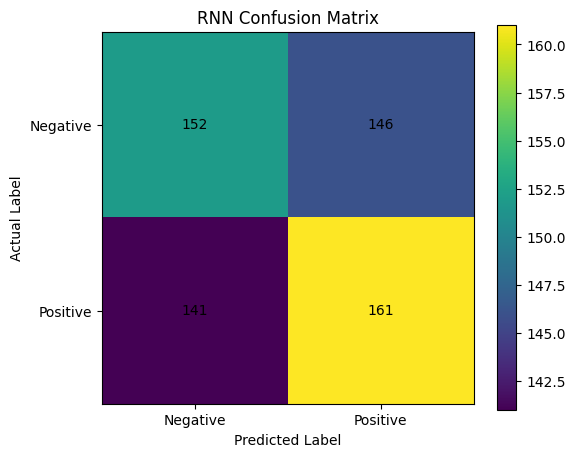

In [117]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("RNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.show()

In [118]:
def predict_sentiment(text):

    movie.eval()

    # Tokenize
    encoded = encode_text(text)

    # Pad / truncate
    processed = pad_or_truncate(encoded)

    # Convert to tensor
    input_tensor = torch.tensor(
        [processed],
        dtype=torch.long
    ).to(device)

    with torch.no_grad():

        logit = movie(input_tensor)

        probability = torch.sigmoid(
            logit
        ).item()

    if probability >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    return sentiment, probability

In [119]:
review = "This movie was absolutely amazing. I really enjoyed every moment of it."

sentiment, probability = predict_sentiment(
    review
)

print("Review:")
print(review)

print("\nPrediction:", sentiment)
print("Probability:", probability)

Review:
This movie was absolutely amazing. I really enjoyed every moment of it.

Prediction: Positive
Probability: 0.5911107063293457


In [120]:
review = "This movie was terrible, boring and a complete waste of time."

sentiment, probability = predict_sentiment(
    review
)

print("Review:")
print(review)

print("\nPrediction:", sentiment)
print("Probability:", probability)

Review:
This movie was terrible, boring and a complete waste of time.

Prediction: Negative
Probability: 0.4844540059566498


In [121]:
review = "The acting was excellent and the story was fantastic."

sentiment, probability = predict_sentiment(
    review
)

print("Review:")
print(review)

print("\nPrediction:", sentiment)
print("Probability:", probability)

Review:
The acting was excellent and the story was fantastic.

Prediction: Positive
Probability: 0.517935037612915
